Setup complete.
Modeling table shape:
(4088, 28)

Number of features:
20

Release years:
release_year
2015.0     751
2016.0    1004
2017.0    1107
2018.0     637
2019.0     241
2020.0     123
2021.0      87
2022.0      62
2023.0      47
2024.0      29
Name: count, dtype: int64
(109, 8)


,model,n_games,MAE,RMSE,R2
2,Tuned Gradient Boosting,109,0.715636,0.934892,0.043847


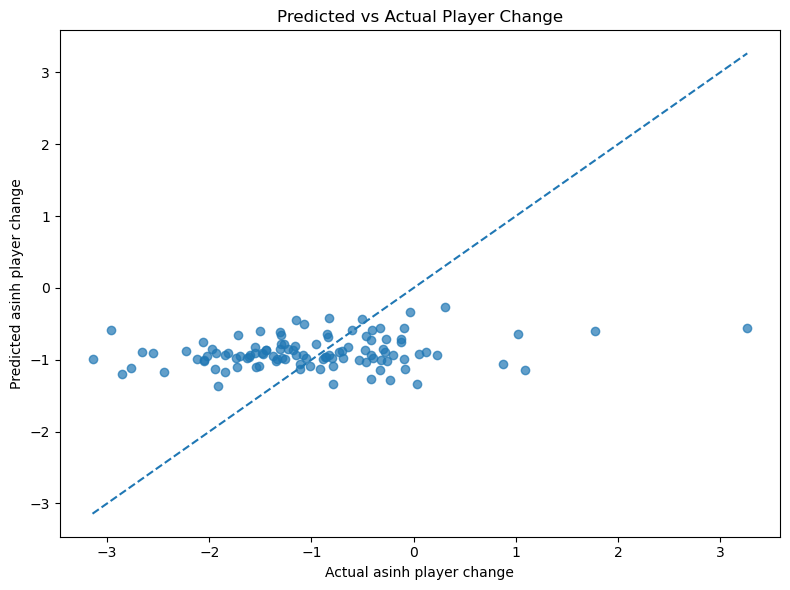

Serialized model loaded successfully.
Sample predictions:
[-0.79025435 -1.06325905 -1.06566432 -0.92139561 -0.96459313]


In [12]:
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
)
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


PROJECT_DIR = Path(r"C:\Projects\data-science")

sys.path.insert(
    0,
    str(PROJECT_DIR),
)

DATA_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "steam_modeling_data_large.csv"
)

RESULTS_DIR = (
    PROJECT_DIR
    / "results"
    / "final"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

ARTIFACTS_DIR = PROJECT_DIR / "artifacts"

from src.models.train import (
    TARGET,
    get_feature_columns,
    build_pipeline,
    build_final_gradient_boosting,
)

print("Setup complete.")

modeling_table = pd.read_csv(
    DATA_PATH
)

feature_cols = get_feature_columns(
    modeling_table
)

target = TARGET

print("Modeling table shape:")
print(modeling_table.shape)

print("\nNumber of features:")
print(len(feature_cols))

print("\nRelease years:")
print(
    modeling_table["release_year"]
    .value_counts()
    .sort_index()
)

def evaluate_final_model(
    model_name,
    model,
    modeling_table,
    feature_cols,
    target,
):
    predictions_all = []

    test_settings = [
        {
            "test_year": 2022,
            "train_end": 2020,
        },
        {
            "test_year": 2023,
            "train_end": 2021,
        },
    ]

    for setting in test_settings:

        train_df = modeling_table[
            modeling_table["release_year"]
            <= setting["train_end"]
        ].copy()

        test_df = modeling_table[
            modeling_table["release_year"]
            == setting["test_year"]
        ].copy()

        X_train = train_df[feature_cols]
        y_train = train_df[target]

        X_test = test_df[feature_cols]
        y_test = test_df[target]

        pipeline = build_pipeline(
            model
        )

        pipeline.fit(
            X_train,
            y_train,
        )

        predictions = pipeline.predict(
            X_test
        )

        year_results = pd.DataFrame({
            "appid": test_df["appid"].values,
            "name": test_df["name"].values,
            "release_year": test_df["release_year"].values,
            "actual": y_test.values,
            "prediction": predictions,
        })

        year_results["residual"] = (
            year_results["actual"]
            - year_results["prediction"]
        )

        year_results["absolute_error"] = (
            np.abs(
                year_results["residual"]
            )
        )

        year_results["model"] = model_name

        predictions_all.append(
            year_results
        )

    predictions_all = pd.concat(
        predictions_all,
        ignore_index=True,
    )

    metrics = {
        "model": model_name,
        "n_games": len(predictions_all),
        "MAE": mean_absolute_error(
            predictions_all["actual"],
            predictions_all["prediction"],
        ),
        "RMSE": np.sqrt(
            mean_squared_error(
                predictions_all["actual"],
                predictions_all["prediction"],
            )
        ),
        "R2": r2_score(
            predictions_all["actual"],
            predictions_all["prediction"],
        ),
    }

    return metrics, predictions_all

models = {
    "Dummy Median": DummyRegressor(
        strategy="median"
    ),

    "Linear Regression": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
    ),

    "Tuned Gradient Boosting":
        GradientBoostingRegressor(
            n_estimators=100,
            learning_rate=0.05,
            max_depth=2,
            random_state=42,
        ),
}

comparison_rows = []

prediction_tables = {}

for model_name, model in models.items():

    metrics, predictions = (
        evaluate_final_model(
            model_name=model_name,
            model=model,
            modeling_table=modeling_table,
            feature_cols=feature_cols,
            target=target,
        )
    )

    comparison_rows.append(
        metrics
    )

    prediction_tables[
        model_name
    ] = predictions


final_model_comparison = (
    pd.DataFrame(
        comparison_rows
    )
    .sort_values("MAE")
    .reset_index(drop=True)
)

final_model_comparison

final_model_comparison.to_csv(
    RESULTS_DIR / "final_model_comparison.csv",
    index=False,
)

gb_predictions = prediction_tables[
    "Tuned Gradient Boosting"
].copy()

gb_metrics = final_model_comparison[
    final_model_comparison["model"]
    == "Tuned Gradient Boosting"
].copy()

print(gb_predictions.shape)
display(gb_metrics)


plt.figure(
    figsize=(8, 6)
)

plt.scatter(
    gb_predictions["actual"],
    gb_predictions["prediction"],
    alpha=0.7,
)

plot_min = min(
    gb_predictions["actual"].min(),
    gb_predictions["prediction"].min(),
)

plot_max = max(
    gb_predictions["actual"].max(),
    gb_predictions["prediction"].max(),
)

plt.plot(
    [plot_min, plot_max],
    [plot_min, plot_max],
    linestyle="--",
)

plt.xlabel(
    "Actual asinh player change"
)

plt.ylabel(
    "Predicted asinh player change"
)

plt.title(
    "Predicted vs Actual Player Change"
)

plt.tight_layout()

plt.savefig(
    RESULTS_DIR
    / "predicted_vs_actual.png",
    dpi=300,
    bbox_inches="tight",
)

plt.show()


MODEL_PATH = (
    ARTIFACTS_DIR
    / "final_model.joblib"
)

saved_model = joblib.load(
    MODEL_PATH
)

sample_predictions = (
    saved_model.predict(
        modeling_table[
            feature_cols
        ].head(5)
    )
)

print(
    "Serialized model loaded successfully."
)

print(
    "Sample predictions:"
)

print(
    sample_predictions
)